# Get started with ChakraTS

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yhatlabs/yhatlabs-cookbook/blob/main/getting-started/chakrats.ipynb)

ChakraTS forecasts any time series from its history, with a range of likely values around every step and no training
on your data. In this notebook you forecast a week of electricity demand in Texas, check the model on past days, give it
what you know about the future, and fine-tune it on your series.

You need an API key: create one at https://yhatlabs.com/models/signup.

In [1]:
%pip install -q -U "yhatlabs[plot]" "datasets>=4"

In [2]:
import os
try:  # in Colab: add YHAT_API_KEY under Secrets (the key icon on the left)
    from google.colab import userdata
    os.environ.setdefault("YHAT_API_KEY", userdata.get("YHAT_API_KEY"))
except Exception:
    pass
if not os.environ.get("YHAT_API_KEY"):  # elsewhere: paste it here, or set it in your environment beforehand
    import getpass
    os.environ["YHAT_API_KEY"] = getpass.getpass("YHAT_API_KEY (from https://yhatlabs.com/models): ")

In [3]:
from yhatlabs import Client

yh = Client()  # reads YHAT_API_KEY

## 1. Load some history

One row per series and hour: the series id, the timestamp and the value.

In [4]:
import datasets
import pandas as pd

ercot = datasets.load_dataset("autogluon/fev_datasets", "ercot_1H", split="train")
df = pd.concat(pd.DataFrame({"unique_id": r["id"], "ds": r["timestamp"], "y": r["target"]}) for r in ercot)
df = df[df["ds"] > df["ds"].max() - pd.Timedelta(weeks=8)].reset_index(drop=True)  # the last 8 weeks of every region

cutoff = df["ds"].max() - pd.Timedelta(hours=168)
history, actual = df[df["ds"] <= cutoff], df[df["ds"] > cutoff]  # forecast the last week, then compare with what happened
print(f"{df['unique_id'].nunique()} regions, hourly, {history['ds'].min():%Y-%m-%d} to {history['ds'].max():%Y-%m-%d}")

8 regions, hourly, 2021-07-07 to 2021-08-25


## 2. Forecast a week ahead

`level=[80, 95]` asks for two ranges around the median: the actual value should fall inside the 80% range about 80% of the time.

In [5]:
fc = yh.forecast(history, h=168, level=[80, 95])
fc_df = fc.df
fc_df.head()

,unique_id,ds,q2.5,q10,median,q90,q97.5
0,COAST,2021-08-25 01:00:00,15001.187500,15036.402344,15095.928711,15187.567383,15269.137695
1,COAST,2021-08-25 02:00:00,14201.998047,14276.955078,14388.836914,14518.162109,14636.123047
2,COAST,2021-08-25 03:00:00,13575.585938,13716.271484,13874.878906,14000.130859,14091.599609
3,COAST,2021-08-25 04:00:00,13234.207031,13395.964844,13586.058594,13747.412109,13859.587891
4,COAST,2021-08-25 05:00:00,13165.755859,13326.412109,13540.262695,13727.058594,13849.496094


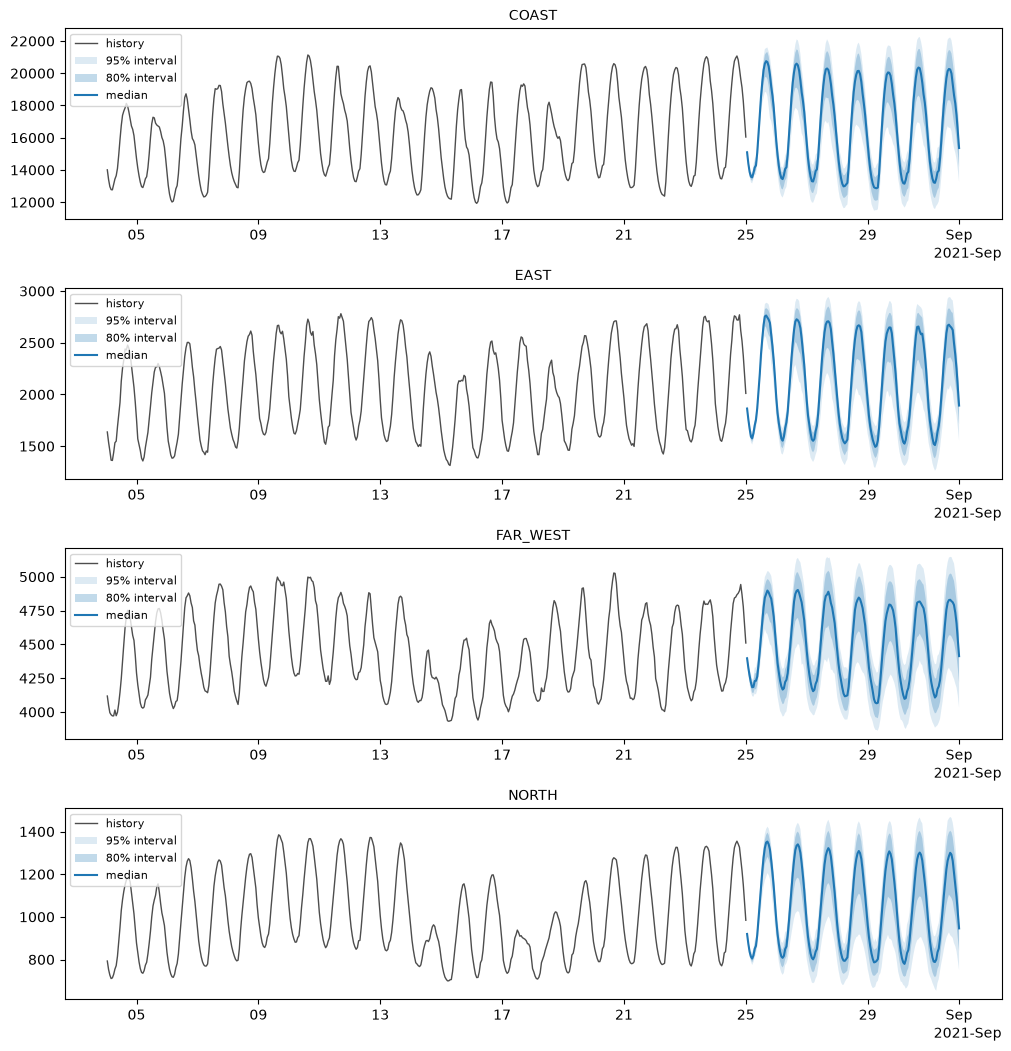

In [6]:
fc.plot(history=history);

Compare with what actually happened that week:

In [7]:
scored = fc_df.merge(actual, on=["unique_id", "ds"])
error = ((scored["median"] - scored["y"]).abs() / scored["y"]).mean()
inside = ((scored["y"] >= scored["q10"]) & (scored["y"] <= scored["q90"])).mean()
print(f"The median is off by {error:.1%} on average, and {inside:.0%} of the actual values fall inside the 80% range.")

The median is off by 3.6% on average, and 91% of the actual values fall inside the 80% range.


## 3. Check it on your own history

`evaluate` goes back to several points in the past, forecasts from each, and scores the forecasts against what happened, next to a simple seasonal forecast (the same hour a day earlier). `skill_mase` above 0 means ChakraTS beats it.

In [8]:
ev = yh.evaluate(df, h=24, windows=7)  # each of the last 7 days, 24 hours ahead
ev.summary

,mase,sql,wql,mae,rmse,coverage@0.8,skill_mase,skill_sql,skill_wql,skill_mae,skill_rmse
model,,,,,,,,,,,
chakra-ts,0.598323,0.458994,0.020231,211.918891,268.290692,0.773065,0.315836,0.401082,0.401082,0.315836,0.292877
seasonal_naive,0.877858,0.729316,0.032025,314.501886,379.102959,0.848214,0.000000,0.000000,0.000000,0.000000,0.000000


## 4. Use what you know about the future

Electricity prices depend on demand and wind, and grid operators publish forecasts of both a day ahead. Give those columns to the model as `known` inputs: their values over the next 24 hours sit in the same table.

In [9]:
np_ = datasets.load_dataset("autogluon/fev_datasets", "epf_np", split="train")[0]
prices = pd.DataFrame({"unique_id": "Nord Pool", "ds": np_["timestamp"], "y": np_["target"],
                       "load_forecast": np_["Grid load forecast"], "wind_forecast": np_["Wind power forecast"]})
prices = prices.iloc[-24 * 7 * 12:].reset_index(drop=True)  # the last 12 weeks, hourly
prices.tail(3)

,unique_id,ds,y,load_forecast,wind_forecast
2013,Nord Pool,2018-12-24 21:00:00,49.090000,51488.0,2919.0
2014,Nord Pool,2018-12-24 22:00:00,49.020000,50928.0,3119.0
2015,Nord Pool,2018-12-24 23:00:00,48.099998,49889.0,3306.0


In [10]:
history_only = yh.evaluate(prices[["unique_id", "ds", "y"]], h=24, windows=7)
with_forecasts = yh.evaluate(prices, h=24, windows=7, known=["load_forecast", "wind_forecast"])
pd.DataFrame({"history only": history_only.summary.iloc[0][["mase", "wql"]],
              "with load and wind forecasts": with_forecasts.summary.iloc[0][["mase", "wql"]]})

,history only,with load and wind forecasts
mase,0.830802,0.336911
wql,0.045396,0.018038


## 5. Fine-tune on your series

`tune` adapts the model to your history in a few minutes. It holds out the last `h` steps, and the tuned model is used only if it beats the original there.

In [11]:
tuned = yh.tune(history, h=24)
print("tune used:", tuned.used)
tuned.holdout

tune used: True


{'window': 24,
 'series': 8,
 'zero_shot': {'loss': 0.1379, 'wape': 0.0162},
 'tuned': {'loss': 0.1223, 'wape': 0.0131}}

In [12]:
fc_tuned = tuned.forecast(history, h=168)
fc_tuned.df.head()

,unique_id,ds,q10,median,q90
0,COAST,2021-08-25 01:00:00,15037.662109,15109.103516,15245.972656
1,COAST,2021-08-25 02:00:00,14232.328125,14380.527344,14607.050781
2,COAST,2021-08-25 03:00:00,13620.273438,13857.207031,14066.531250
3,COAST,2021-08-25 04:00:00,13228.290039,13569.254883,13879.716797
4,COAST,2021-08-25 05:00:00,13163.332031,13502.151367,13731.861328


*Data: hourly electricity demand of the eight ERCOT weather zones in Texas (public ERCOT data, via [neuralprophet-data](https://github.com/ourownstory/neuralprophet-data)); Nord Pool day-ahead prices with the published load and wind forecasts, from [Lago et al. (2021)](https://zenodo.org/records/4624805) (CC BY 4.0). Both are loaded from [autogluon/fev_datasets](https://huggingface.co/datasets/autogluon/fev_datasets).*

## Next steps

- [Docs](https://yhatlabs.com/models/docs): every option of `forecast`, `evaluate` and `tune`
- [Benchmarks](../benchmarks): our leaderboard results and how to reproduce them
- Questions: founders@yhatlabs.com